In [11]:

import os

PROJECT_DIR = r"C:\workspace\projects\IRM"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

for root, dirs, files in os.walk(DATA_DIR):
    relative_path = os.path.relpath(root, PROJECT_DIR)
    depth = relative_path.count(os.sep)

    if depth >= 3:
        dirs[:] = []

    print(f"\n{relative_path}/")

    for file in sorted(files)[:10]:
        print("    ", file)

    if len(files) > 10:
        print(f"     ... and {len(files) - 10} more files")



data/

data\processed/
     .gitkeep

data\raw/
     .gitkeep

data\raw\Train/

data\raw\Train\Glioma/

data\raw\Train\Meningioma/

data\raw\Train\No Tumor/

data\raw\Train\Pituitary/

data\raw\Val/

data\raw\Val\Glioma/

data\raw\Val\Meningioma/

data\raw\Val\No Tumor/

data\raw\Val\Pituitary/

data\yolo/
     .gitkeep

data\yolo\images/

data\yolo\images\test/
     .gitkeep

data\yolo\images\train/
     .gitkeep

data\yolo\images\val/
     .gitkeep

data\yolo\labels/

data\yolo\labels\test/
     .gitkeep

data\yolo\labels\train/
     .gitkeep

data\yolo\labels\val/
     .gitkeep


In [12]:

import os
import tensorflow as tf

# Dataset paths
PROJECT_DIR = r"C:\workspace\projects\IRM"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")

TRAIN_DIR = os.path.join(DATA_DIR, "Train")
VAL_DIR = os.path.join(DATA_DIR, "Val")

# Image settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load validation images
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Display the classes
class_names = train_dataset.class_names

print("\nClasses:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())


Found 4737 files belonging to 4 classes.
Found 512 files belonging to 4 classes.

Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
Training batches: 149
Validation batches: 16


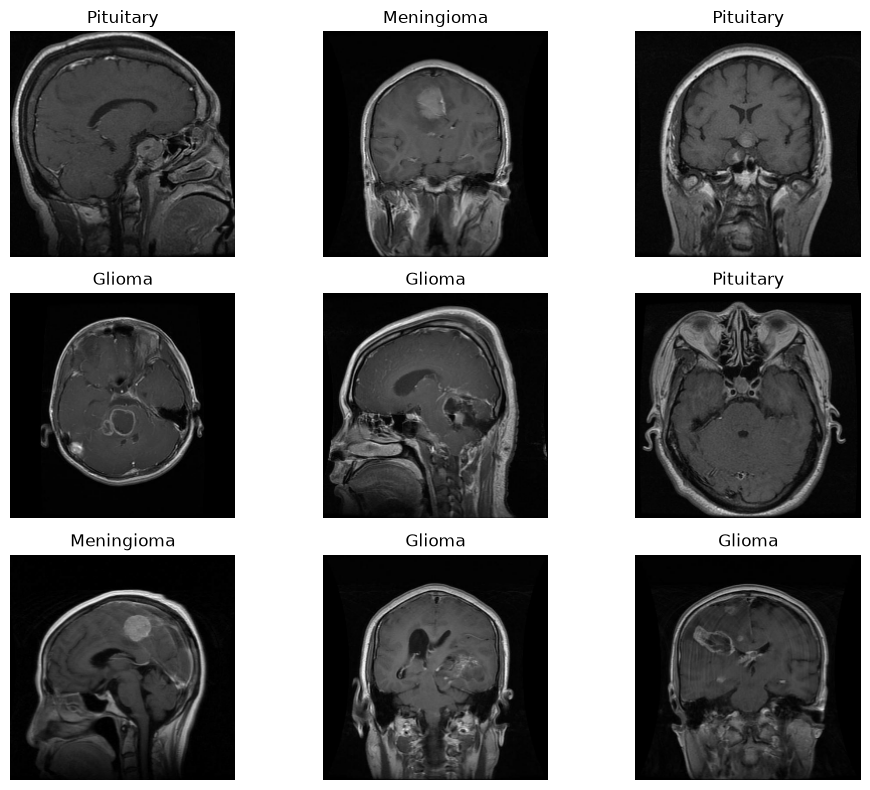

In [13]:

import matplotlib.pyplot as plt

for images, labels in train_dataset.take(1):
    plt.figure(figsize=(10, 8))

    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [14]:

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Apply MobileNetV2 preprocessing
train_dataset = train_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prepare batches efficiently
train_dataset = train_dataset.prefetch(
    buffer_size=tf.data.AUTOTUNE
)

val_dataset = val_dataset.prefetch(
    buffer_size=tf.data.AUTOTUNE
)

print("Datasets prepared for MobileNetV2!")


Datasets prepared for MobileNetV2!


In [15]:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Load the pretrained MobileNetV2 base
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Build the classification model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(len(class_names), activation="softmax")
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    MODEL_DIR,
    "mobilenetv2_best.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks configured.")
print("Best model will be saved to:", checkpoint_path)


Callbacks configured.
Best model will be saved to: C:\workspace\projects\IRM\models\mobilenetv2_best.keras


In [17]:

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10


c:\workspace\projects\IRM\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.7944 - loss: 0.5199
Epoch 1: val_loss improved from None to 0.31981, saving model to C:\workspace\projects\IRM\models\mobilenetv2_best.keras

Epoch 1: finished saving model to C:\workspace\projects\IRM\models\mobilenetv2_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 35s 200ms/step - accuracy: 0.7944 - loss: 0.5199 - val_accuracy: 0.8730 - val_loss: 0.3198
Epoch 2/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.8877 - loss: 0.3055
Epoch 2: val_loss did not improve from 0.31981
149/149 ━━━━━━━━━━━━━━━━━━━━ 45s 300ms/step - accuracy: 0.8877 - loss: 0.3055 - val_accuracy: 0.8398 - val_loss: 0.3864
Epoch 3/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step - accuracy: 0.8934 - loss: 0.2819
Epoch 3: val_loss improved from 0.31981 to 0.19751, saving model to C:\workspace\projects\IRM\models\mobilenetv2_best.keras

Epoch 3: finished saving model to C:\workspace\projects\IRM\models\mobilenetv2_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 109s

16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 422ms/step
              precision    recall  f1-score   support

      Glioma     0.9773    0.9485    0.9627       136
  Meningioma     0.9552    0.9143    0.9343       140
    No Tumor     0.9901    1.0000    0.9950       100
   Pituitary     0.9379    1.0000    0.9680       136

    accuracy                         0.9629       512
   macro avg     0.9651    0.9657    0.9650       512
weighted avg     0.9633    0.9629    0.9626       512



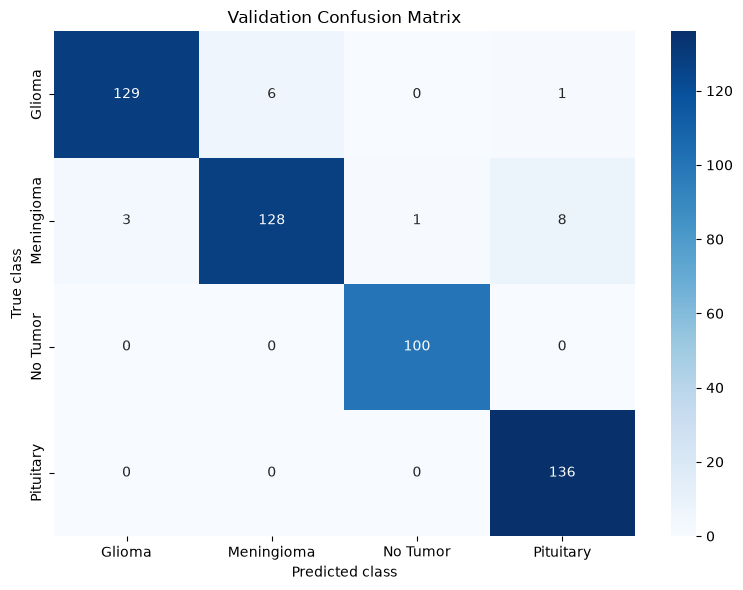

In [20]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get the true labels from the validation dataset
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_dataset
])

# Get the model's predictions
y_prob = model.predict(val_dataset)
y_pred = np.argmax(y_prob, axis=1)

# Display precision, recall, and F1-score for each class
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Display the confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [3]:

import os

PROJECT_DIR = r"C:\workspace\projects\IRM"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")

# Find a few annotation files
label_files = []

for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if file.lower().endswith(".txt"):
            label_files.append(os.path.join(root, file))

print("Number of text annotation files:", len(label_files))

# Inspect up to 5 annotation files
for label_path in label_files[:5]:
    print("\nFile:", label_path)

    with open(label_path, "r", encoding="utf-8") as f:
        content = f.read().strip()

    print("Contents:")
    print(content if content else "(empty file)")


Number of text annotation files: 5249

File: C:\workspace\projects\IRM\data\raw\Train\Glioma\labels\gg (1).txt
Contents:
0 0.567383 0.519531 0.189453 0.148438

File: C:\workspace\projects\IRM\data\raw\Train\Glioma\labels\gg (103).txt
Contents:
0 0.414062 0.490234 0.140625 0.132812

File: C:\workspace\projects\IRM\data\raw\Train\Glioma\labels\gg (104).txt
Contents:
0 0.425781 0.486328 0.191406 0.164062

File: C:\workspace\projects\IRM\data\raw\Train\Glioma\labels\gg (105).txt
Contents:
0 0.423828 0.477539 0.187500 0.173828

File: C:\workspace\projects\IRM\data\raw\Train\Glioma\labels\gg (106).txt
Contents:
0 0.420898 0.463867 0.181641 0.150391


In [4]:

import os

PROJECT_DIR = r"C:\workspace\projects\IRM"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")

for split in ["Train", "Val"]:
    split_dir = os.path.join(DATA_DIR, split)

    print(f"\n{'=' * 15} {split} {'=' * 15}")

    if not os.path.isdir(split_dir):
        print("Missing directory:", split_dir)
        continue

    for class_name in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, class_name)

        if not os.path.isdir(class_dir):
            continue

        image_dir = os.path.join(class_dir, "images")
        label_dir = os.path.join(class_dir, "labels")

        # Your dataset may instead store images directly in class_dir
        image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

        if os.path.isdir(image_dir):
            actual_image_dir = image_dir
        else:
            actual_image_dir = class_dir

        image_count = sum(
            1 for name in os.listdir(actual_image_dir)
            if name.lower().endswith(image_extensions)
        )

        label_count = (
            sum(
                1 for name in os.listdir(label_dir)
                if name.lower().endswith(".txt")
            )
            if os.path.isdir(label_dir)
            else 0
        )

        print(
            f"{class_name}: "
            f"{image_count} images, {label_count} label files"
        )



=============== Train ===============
Glioma: 1153 images, 1153 label files
Meningioma: 1449 images, 1449 label files
No Tumor: 711 images, 711 label files
Pituitary: 1424 images, 1424 label files

=============== Val ===============
Glioma: 136 images, 136 label files
Meningioma: 140 images, 140 label files
No Tumor: 100 images, 100 label files
Pituitary: 136 images, 136 label files


In [5]:

import os

PROJECT_DIR = r"C:\workspace\projects\IRM"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")

classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

total_labels = 0
empty_labels = 0
invalid_labels = []
class_id_counts = {}

for split in ["Train", "Val"]:
    for class_name in classes:
        label_dir = os.path.join(
            DATA_DIR, split, class_name, "labels"
        )

        if not os.path.isdir(label_dir):
            print("Missing label directory:", label_dir)
            continue

        for filename in os.listdir(label_dir):
            if not filename.lower().endswith(".txt"):
                continue

            total_labels += 1
            label_path = os.path.join(label_dir, filename)

            with open(label_path, "r", encoding="utf-8") as f:
                lines = [line.strip() for line in f if line.strip()]

            if not lines:
                empty_labels += 1
                continue

            for line_number, line in enumerate(lines, start=1):
                parts = line.split()

                try:
                    if len(parts) != 5:
                        raise ValueError("Expected 5 values")

                    class_id = int(parts[0])
                    x_center, y_center, width, height = map(
                        float, parts[1:]
                    )

                    if class_id < 0:
                        raise ValueError("Negative class ID")

                    if not (
                        0 <= x_center <= 1
                        and 0 <= y_center <= 1
                        and 0 < width <= 1
                        and 0 < height <= 1
                    ):
                        raise ValueError("Coordinates out of range")

                    # Check that the full box fits inside the image
                    if (
                        x_center - width / 2 < 0
                        or x_center + width / 2 > 1
                        or y_center - height / 2 < 0
                        or y_center + height / 2 > 1
                    ):
                        raise ValueError("Box extends outside image")

                    class_id_counts[class_id] = (
                        class_id_counts.get(class_id, 0) + 1
                    )

                except (ValueError, OverflowError) as e:
                    invalid_labels.append(
                        f"{label_path} | line {line_number}: "
                        f"{e} | {line}"
                    )

print("Total label files:", total_labels)
print("Empty label files:", empty_labels)
print("Class ID counts:", class_id_counts)
print("Invalid annotation lines:", len(invalid_labels))

for error in invalid_labels[:20]:
    print(error)


Total label files: 5249
Empty label files: 1
Class ID counts: {0: 1502, 3: 1936, 1: 1624, 2: 796}
Invalid annotation lines: 15
C:\workspace\projects\IRM\data\raw\Train\No Tumor\labels\3.txt | line 1: Box extends outside image | 2 0.512397 0.513051 0.770248 0.973899
C:\workspace\projects\IRM\data\raw\Train\No Tumor\labels\image (11).txt | line 1: Box extends outside image | 2 0.501969 0.502525 0.996063 0.994949
C:\workspace\projects\IRM\data\raw\Train\No Tumor\labels\image (58).txt | line 1: Box extends outside image | 2 0.502119 0.448148 0.995763 0.792593
C:\workspace\projects\IRM\data\raw\Train\No Tumor\labels\image(110).txt | line 1: Box extends outside image | 2 0.502119 0.321038 0.995763 0.631148
C:\workspace\projects\IRM\data\raw\Train\No Tumor\labels\image(116).txt | line 1: Box extends outside image | 2 0.502128 0.430556 0.995745 0.851852
C:\workspace\projects\IRM\data\raw\Train\No Tumor\labels\image(231).txt | line 1: Box extends outside image | 2 0.504532 0.488916 0.990937 0.9

In [6]:
import os
import shutil
import yaml
from PIL import Image

PROJECT_DIR = r"C:\workspace\projects\IRM"
RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
YOLO_DIR = os.path.join(PROJECT_DIR, "data", "yolo")

CLASSES = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3
}

SPLITS = {
    "Train": "train",
    "Val": "val"
}

# Create output directories
for split in ["train", "val"]:
    os.makedirs(os.path.join(YOLO_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DIR, "labels", split), exist_ok=True)

copied_images = 0
issues = []

for source_split, target_split in SPLITS.items():
    for class_name, class_id in CLASSES.items():

        class_dir = os.path.join(RAW_DIR, source_split, class_name)
        source_images_dir = os.path.join(class_dir, "images")
        source_labels_dir = os.path.join(class_dir, "labels")

        if not os.path.isdir(source_images_dir):
            source_images_dir = class_dir

        for filename in os.listdir(source_images_dir):

            image_path = os.path.join(source_images_dir, filename)
            stem = os.path.splitext(filename)[0]
            label_path = os.path.join(source_labels_dir, stem + ".txt")

            if not os.path.isfile(label_path):
                issues.append(f"Missing label: {image_path}")
                continue

            try:
                with Image.open(image_path) as image:
                    image.verify()
            except Exception:
                issues.append(f"Unreadable image: {image_path}")
                continue

            new_stem = f"{target_split}_{class_id}_{stem}"

            output_image = os.path.join(
                YOLO_DIR, "images", target_split, new_stem + ".jpg"
            )
            output_label = os.path.join(
                YOLO_DIR, "labels", target_split, new_stem + ".txt"
            )

            with open(label_path, "r") as file:
                label_content = file.read()

            shutil.copy2(image_path, output_image)

            with open(output_label, "w") as file:
                file.write(label_content)

            copied_images += 1

# Create YOLO configuration
data_config = {
    "path": os.path.abspath(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "Glioma",
        1: "Meningioma",
        2: "No Tumor",
        3: "Pituitary"
    }
}

yaml_path = os.path.join(YOLO_DIR, "data.yaml")

with open(yaml_path, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print("Dataset preparation finished.")
print("Images copied:", copied_images)
print("Issues found:", len(issues))
print("Configuration:", yaml_path)

for issue in issues[:10]:
    print(issue)

Dataset preparation finished.
Images copied: 5247
Issues found: 2
Configuration: C:\workspace\projects\IRM\data\yolo\data.yaml
Missing label: C:\workspace\projects\IRM\data\raw\Val\No Tumor\images\image(55).jpg
Missing label: C:\workspace\projects\IRM\data\raw\Val\No Tumor\images\image(61).jpg


In [7]:

import os
import shutil
import random
import yaml

PROJECT_DIR = r"C:\workspace\projects\IRM"
RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
YOLO_DIR = os.path.join(PROJECT_DIR, "data", "yolo")

random.seed(42)

CLASSES = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3
}

# Remove previously generated YOLO images and labels
for folder in ["images", "labels"]:
    folder_path = os.path.join(YOLO_DIR, folder)

    for name in os.listdir(folder_path):
        path = os.path.join(folder_path, name)

        if os.path.isdir(path):
            shutil.rmtree(path)
        else:
            os.remove(path)

# Create output directories
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(YOLO_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DIR, "labels", split), exist_ok=True)

counts = {"train": 0, "val": 0, "test": 0}

# Split original training data into 70% train and 15% validation
for class_name, class_id in CLASSES.items():
    class_dir = os.path.join(RAW_DIR, "Train", class_name)
    images_dir = os.path.join(class_dir, "images")
    labels_dir = os.path.join(class_dir, "labels")

    files = os.listdir(images_dir)
    random.shuffle(files)

    train_end = int(len(files) * 0.70)
    val_end = int(len(files) * 0.85)

    splits = {
        "train": files[:train_end],
        "val": files[train_end:val_end]
    }

    for split, selected_files in splits.items():
        for filename in selected_files:
            stem = os.path.splitext(filename)[0]
            label_src = os.path.join(labels_dir, stem + ".txt")

            if not os.path.isfile(label_src):
                print("Missing label:", label_src)
                continue

            new_stem = f"{split}_{class_id}_{stem}"

            shutil.copy2(
                os.path.join(images_dir, filename),
                os.path.join(YOLO_DIR, "images", split, new_stem + ".jpg")
            )
            shutil.copy2(
                label_src,
                os.path.join(YOLO_DIR, "labels", split, new_stem + ".txt")
            )

            counts[split] += 1

# Use original Val data as the held-out test set
for class_name, class_id in CLASSES.items():
    class_dir = os.path.join(RAW_DIR, "Val", class_name)
    images_dir = os.path.join(class_dir, "images")
    labels_dir = os.path.join(class_dir, "labels")

    for filename in os.listdir(images_dir):
        stem = os.path.splitext(filename)[0]
        label_src = os.path.join(labels_dir, stem + ".txt")

        if not os.path.isfile(label_src):
            print("Missing label:", label_src)
            continue

        new_stem = f"test_{class_id}_{stem}"

        shutil.copy2(
            os.path.join(images_dir, filename),
            os.path.join(YOLO_DIR, "images", "test", new_stem + ".jpg")
        )
        shutil.copy2(
            label_src,
            os.path.join(YOLO_DIR, "labels", "test", new_stem + ".txt")
        )

        counts["test"] += 1

# Save YOLO configuration
data_config = {
    "path": os.path.abspath(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "Glioma",
        1: "Meningioma",
        2: "No Tumor",
        3: "Pituitary"
    }
}

with open(os.path.join(YOLO_DIR, "data.yaml"), "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print("\nDataset preparation complete:")
for split, count in counts.items():
    print(f"{split}: {count} images")

print("\nYOLO configuration saved.")


Missing label: C:\workspace\projects\IRM\data\raw\Val\No Tumor\labels\image(55).txt
Missing label: C:\workspace\projects\IRM\data\raw\Val\No Tumor\labels\image(61).txt

Dataset preparation complete:
train: 3314 images
val: 711 images
test: 510 images

YOLO configuration saved.


In [ ]:

import os
from ultralytics import YOLO

PROJECT_DIR = r"C:\workspace\projects\IRM"
DATA_YAML = os.path.join(PROJECT_DIR, "data", "yolo", "data.yaml")

# Load pretrained YOLO nano weights
model = YOLO("yolo26n.pt")

# Train
results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=8,
    patience=7,
    workers=0,
    project=os.path.join(PROJECT_DIR, "runs", "detect"),
    name="mri_yolo_v1",
    exist_ok=True
)

print("Training finished.")
print("Best model:", os.path.join(
    PROJECT_DIR, "runs", "detect", "mri_yolo_v1", "weights", "best.pt"
))


New https://pypi.org/project/ultralytics/8.4.193 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.192  Python-3.12.10 torch-2.15.0+cpu CPU (Intel Core Ultra 7 165H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\workspace\projects\IRM\data\yolo\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.